# Bloque 1 Librerias

In [85]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
rng = np.random.default_rng(42)
print("Listo")

Listo


# Bloque 2 Cargar el dataset desde tu computadora 

In [86]:
RUTA="datos/wdbc.data"
datos = pd.read_csv(RUTA, header=None)

print("Cantidad de columnas: ", datos.shape[1])

X = datos.iloc[:, 2:]
y = (datos.iloc[:, 1] == "M").astype(int)

print("Caracteristicas: ",X.shape[1])
print("Muestras: ", X.shape[0])

Cantidad de columnas:  32
Caracteristicas:  30
Muestras:  569


# Bloque 3 Separar entrenamiento y pruebas

In [87]:
X = datos.iloc[:, 2:].to_numpy(float)
y = (datos.iloc[:, 1] == "M").astype(int).to_numpy()

indices = rng.permutation(len(X))
corte = int(0.8 * len(X))

X_ent = X[indices[:corte]]
X_pru = X[indices[corte:]]

y_ent = y[indices[:corte]]
y_pru = y[indices[corte:]]

print("Entrenamiento: ", len(X_ent))
print("Prueba: ", len(X_pru))
print("Caracteristicas: ", X.shape[1])

Entrenamiento:  455
Prueba:  114
Caracteristicas:  30


# Bloque 4 Normalizar las entradas

In [88]:
minimos = X_ent.min(axis=0)
rangos = X_ent.max(axis=0) - minimos
rangos[rangos == 0] = 1

X_ent = (X_ent - minimos) / rangos
X_pru = (X_pru - minimos) / rangos

# Bloque 5 Definir como se clasifica el cromosoma

In [89]:
def probabilidad(cromosoma, X):
    z = X @ cromosoma[:-1] + cromosoma[-1]
    z = np.clip(z, -30, 30)
    return 1 / (1 + np.exp(-z))

def clasificar(cromosoma, X):
    return (probabilidad(cromosoma, X) >= 0.5).astype(int)

# Bloque 6 Fitnes: F1

In [90]:
def fitness(cromosoma, X, y):
    pred = clasificar(cromosoma, X)
    vp = np.sum((pred == 1) & (y == 1))
    fp = np.sum((pred == 1) & (y == 0))
    fn = np.sum((pred == 0) & (y == 1))
    return 2 * vp / max(2 * vp + fp + fn, 1)

# Bloque 7 Configuracion e inicializacion de poblacion

In [91]:
POBLACION = 100
GENERACIONES = 100
PROB_CRUCE = 0.80
PROB_MUTACION = 0.10

NUMERO_GENES = X_ent.shape[1] + 1

poblacion = rng.uniform(-1, 1, (POBLACION, NUMERO_GENES))

print("Individuos: ", len(poblacion))
print("Genes por individuo: ", NUMERO_GENES)

Individuos:  100
Genes por individuo:  31


# Bloque 8 Evaluacion de la poblacion inicial

In [92]:
puntos = np.array([fitness(c, X_ent, y_ent) for c in poblacion])

print("F1 de cada individuo: ", np.round(puntos , 3))
print("Mejor F1 inicial: ", round(puntos.max(), 3))

F1 de cada individuo:  [0.018 0.39  0.184 0.353 0.669 0.672 0.544 0.631 0.556 0.019 0.101 0.
 0.054 0.    0.548 0.542 0.439 0.012 0.735 0.394 0.605 0.544 0.544 0.544
 0.507 0.425 0.    0.032 0.565 0.208 0.503 0.088 0.544 0.    0.558 0.346
 0.453 0.27  0.521 0.353 0.279 0.544 0.769 0.544 0.    0.65  0.48  0.544
 0.    0.226 0.544 0.584 0.    0.543 0.306 0.    0.585 0.011 0.534 0.04
 0.542 0.303 0.    0.07  0.52  0.525 0.46  0.336 0.549 0.011 0.    0.544
 0.609 0.424 0.546 0.276 0.553 0.045 0.053 0.    0.47  0.012 0.155 0.639
 0.5   0.026 0.544 0.    0.079 0.043 0.011 0.075 0.736 0.    0.149 0.
 0.669 0.621 0.372 0.544]
Mejor F1 inicial:  0.769


# Bloque 9 Seleccion de torneo binario

In [93]:
def torneo(poblacion, puntos):
    a,b = rng.choice(len(poblacion), 2, replace=False)
    ganador = a if puntos[a] >= puntos[b] else b
    return poblacion[ganador].copy()

# Bloque 10 Cruce

In [94]:
def cruce(p1, p2):
    if rng.random() < PROB_CRUCE:
        corte = rng.integers(1, len(p1))
        return np.r_[p1[:corte], p2[corte:]]
    return p1.copy()

# Bloque 11 Mutacion 

In [95]:
def mutacion(cromosoma):
    for i in range(len(cromosoma)):
        if rng.random() < PROB_MUTACION:
            cromosoma[i] += rng.normal(0, 0.4)
    return np.clip(cromosoma, -5, 5)

# Bloque 12 Formar una nueva generacion 

In [96]:
def nueva_generacion(poblacion):
    puntos = np.array([fitness(c, X_ent, y_ent) for c in poblacion])
    nuevos = []
    for _ in range(POBLACION):
        p1 = torneo(poblacion, puntos)
        p2 = torneo(poblacion, puntos)
        nuevos.append(mutacion(cruce(p1,p2)))
    return np.array(nuevos)

# Bloque 13 Ejecutar el algoritmo genetico 

In [97]:
mejor_f1 = -1
historial = []
for g in range(GENERACIONES + 1):
    puntos = np.array([fitness(c, X_ent, y_ent) for c in poblacion])
    i = np.argmax(puntos)
    historial.append(puntos[i])
    if puntos[i] > mejor_f1:
        mejor_f1, mejor = puntos[i], poblacion[i].copy()
    if g % 10 == 0 or g == GENERACIONES:
        print(f"Generacion {g}: mejor F1 = {puntos[i]:.3f}")
    if g < GENERACIONES:
        poblacion = nueva_generacion(poblacion)

Generacion 0: mejor F1 = 0.769
Generacion 10: mejor F1 = 0.903
Generacion 20: mejor F1 = 0.920
Generacion 30: mejor F1 = 0.942
Generacion 40: mejor F1 = 0.934
Generacion 50: mejor F1 = 0.938
Generacion 60: mejor F1 = 0.953
Generacion 70: mejor F1 = 0.973
Generacion 80: mejor F1 = 0.959
Generacion 90: mejor F1 = 0.967
Generacion 100: mejor F1 = 0.971


# Bloque 14 Evaluacion final en datos de prueba

In [98]:
pred = clasificar(mejor,X_pru)
exactitud = np.mean(pred == y_pru)
print("Mejor cromosoma: ", np.round(mejor, 3))
print("Exactitud en prueba: ", round(exactitud, 3))
print("F1 en prueba: ", round(fitness(mejor, X_pru, y_pru), 3))

Mejor cromosoma:  [-0.482  0.16   1.165 -0.43   0.336 -0.037  1.787  0.598  0.39  -1.287
  0.483 -0.395 -0.781  1.398 -0.668 -0.485 -0.341  0.968  0.316  0.282
  3.183  1.624  0.571  1.421  1.961  0.584  0.558 -0.495  0.343 -0.469
 -3.504]
Exactitud en prueba:  0.991
F1 en prueba:  0.988


# Bloque 15 Clasificar registros del dataset

In [99]:
for i in range(min(10, len(X_pru))):
    proba = probabilidad(mejor, X_pru[i:i+1])[0]
    clase = "Maligno" if proba >= 0.5 else "Benigno"
    real = "Maligno" if y_pru[i] == 1 else "Benigno"
    print(f"Caso {i+1}: real={real}, prediccion={clase}, puntuacion={proba:.2f}")

Caso 1: real=Benigno, prediccion=Benigno, puntuacion=0.32
Caso 2: real=Maligno, prediccion=Maligno, puntuacion=0.75
Caso 3: real=Benigno, prediccion=Benigno, puntuacion=0.21
Caso 4: real=Benigno, prediccion=Benigno, puntuacion=0.19
Caso 5: real=Maligno, prediccion=Maligno, puntuacion=0.56
Caso 6: real=Maligno, prediccion=Maligno, puntuacion=0.94
Caso 7: real=Maligno, prediccion=Maligno, puntuacion=0.93
Caso 8: real=Benigno, prediccion=Benigno, puntuacion=0.28
Caso 9: real=Benigno, prediccion=Benigno, puntuacion=0.26
Caso 10: real=Maligno, prediccion=Maligno, puntuacion=0.57


# Bloque 16 Clasificar nuevo caso

In [100]:
caso = np.array([[17.99, 10.38, 122.8, 1001, 0.1184, 0.2776, 0.3001, 0.1471, 0.2419, 0.07871,
                  1.095, 0.9053, 8.589, 153.4, 0.006399, 0.04904, 0.05373, 0.01587, 0.03003, 0.006193,
                  25.38, 17.33, 184.6, 2019, 0.1622, 0.6656, 0.7119, 0.2654, 0.4601, 0.1189]], dtype=float)

print("Valores en el caso:", caso.shape[1], "| esperados:", len(minimos))

caso = (caso - minimos) / rangos
p = probabilidad(mejor, caso)[0]
print("Prediccion: ", "Maligno" if p >= 0.5 else "Benigno")
print("Puntuacion del modelo: ", round(p, 3))

Valores en el caso: 30 | esperados: 30
Prediccion:  Maligno
Puntuacion del modelo:  0.954


# Bloque 17 Grafica de evolucion del F1-score

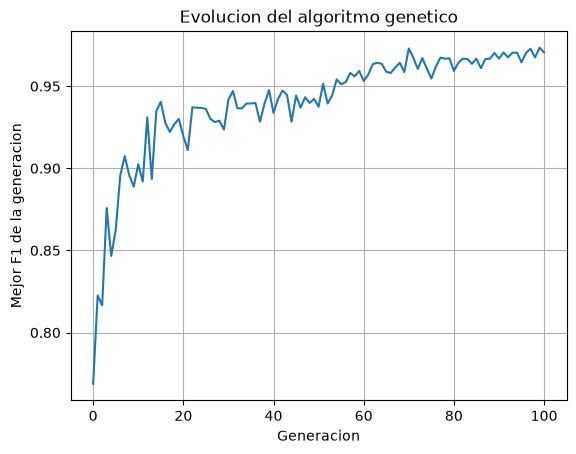

In [101]:
plt.plot(historial)
plt.xlabel("Generacion")
plt.ylabel("Mejor F1 de la generacion")
plt.title("Evolucion del algoritmo genetico")
plt.grid(True)
plt.show()